# Compatibilidad de toda la covarianza latente
## Resumen
El gate de26 comprobaba solo el bloque(X,Z). En18casos poblacionales, acepta cuatro matrices latentes imposibles. La nueva comprobación conjunta las rechaza y conserva los coeficientes cuando la varianza verdadera1se declara correctamente.
## Contexto y métodos
Bajo error clásico independiente $W=Z+v$, se exige
$$S_0=Cov(X,Z,Y)=S-\operatorname{diag}(0,\tau^2,0)\succeq0.$$
Que el bloque de regresores $C=Cov(X,Z)$ sea definido positivo no basta. Si C es PD, el complemento de Schur exige $S_{0,YY}-S_{0,YR}C^{-1}S_{0,RY}\geq0$.
### Supuestos clave
Momentos suministrados/poblacionales, error independiente y varianza externa declarada. PSD es una condición necesaria de compatibilidad; no prueba que esa varianza sea cierta. Float64 con tolerancia1e-10, sin redondeo dirigido.
## Datos
Sin datos empíricos ni MonteCarlo:dosβ(0,.3),nueve varianzas declaradas,18casos exactos. Comparación contra gate26y oráculo independiente Schur.

In [1]:
import json,csv
from pathlib import Path
from IPython.display import display,Image
summary=json.loads(Path('results/joint_summary.json').read_text())
summary

Out[0]: 
{'config': {'research_date': '2026-10-28',
  'effects': [0.0, 0.3],
  'assumed_variances': [0.0, 0.5, 0.9, 1.0, 1.1, 1.15, 1.2, 1.24, 1.5],
  'condition_cap': 100.0,
  'joint_psd_tolerance': 1e-10,
  'latency_repeats': 20,
  'hypothesis': 'joint gate rejects all cases accepted by old gate with negative independent Schur residual; true variance1 preserves coefficients; compatibility does not certify variance truth'},
 'population_cases': 18,
 'method_rows': 36,
 'impossible_accepted_baseline': 4,
 'impossible_accepted_joint': 0,
 'true_variance_coefficients_preserved': True,
 'false_variance_0.5_passes_both': True,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'interpretation': 'Necessary moment compatibility, not causal confidence or proof of external variance'}


## Resultados
Se preserva el experimento26 y su notebook. Este notebook registra solo el incremento28.

In [2]:
rows=list(csv.DictReader(Path('results/joint_cases.csv').open()))
[r for r in rows if r['beta']=='0.0' and r['declared_variance'] in ['1.0','1.2','1.24']]

Out[0]: 
[{'beta': '0.0',
  'declared_variance': '1.0',
  'method': 'regressor_only',
  'status': 'accepted',
  'slope': '-3.628407964397974e-16',
  'schur_residual_variance': '0.25',
  'median_seconds': '5.456499997080755e-05',
  'peak_python_bytes': '2065'},
 {'beta': '0.0',
  'declared_variance': '1.0',
  'method': 'full_joint',
  'status': 'accepted',
  'slope': '-3.628407964397974e-16',
  'schur_residual_variance': '0.25',
  'median_seconds': '9.614350005904271e-05',
  'peak_python_bytes': '2060'},
 {'beta': '0.0',
  'declared_variance': '1.2',
  'method': 'regressor_only',
  'status': 'accepted',
  'slope': '-1.7777777777777748',
  'schur_residual_variance': '-0.19444444444444475',
  'median_seconds': '7.573350001166546e-05',
  'peak_python_bytes': '2021'},
 {'beta': '0.0',
  'declared_variance': '1.2',
  'method': 'full_joint',
  'status': 'incompatible_joint_covariance',
  'slope': '',
  'schur_residual_variance': '-0.19444444444444475',
  'median_seconds': '6.229500002064015e-

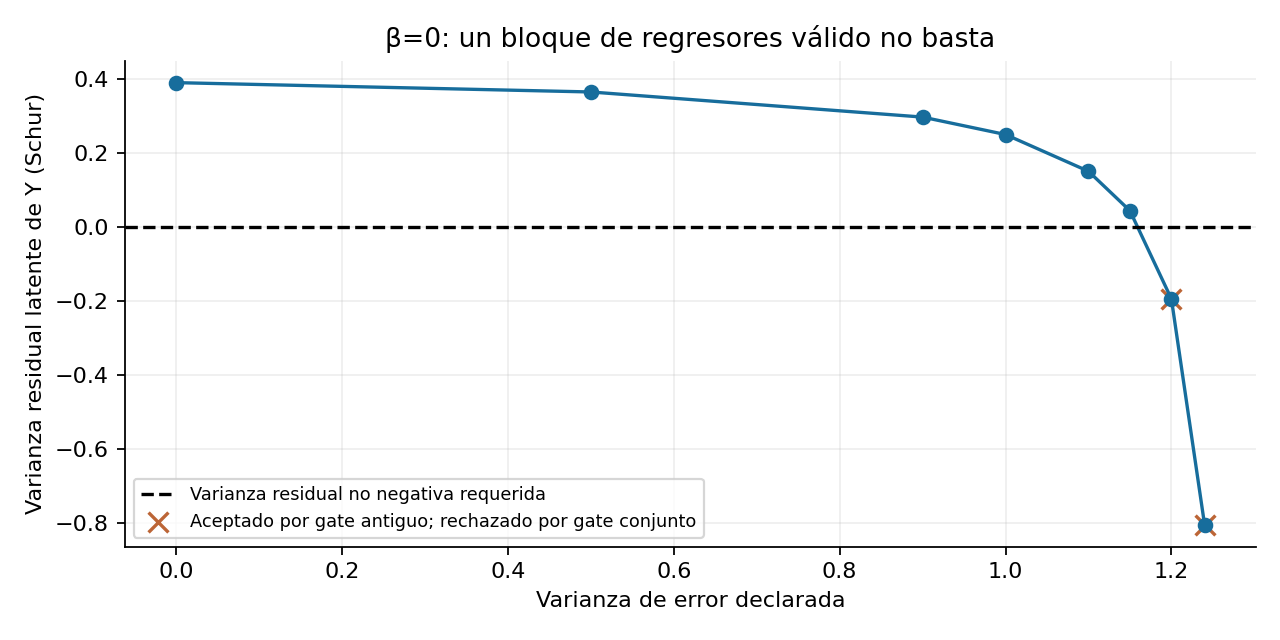

In [3]:
display(Image(filename='results/joint_audit.png'))

## Controles negativos
Una varianza falsa0.5es compatible y pasa ambos gates; no se presenta aceptación como validación causal.

In [4]:
from src.joint_gate import correct_covariance_joint
from src.moments import population_covariance
s=population_covariance(0)
false=correct_covariance_joint(s,.5)
assert false.status=='accepted' and abs(false.slope)>.4
assert summary['impossible_accepted_baseline']==4
assert summary['impossible_accepted_joint']==0
print('Varianza falsa pero compatible:',false)

Varianza falsa pero compatible: Estimate(slope=0.4604316546762591, status='accepted', condition=5.501690937160594)


## Conclusiones
Se cierra una brecha de validación de momentos del26, sin reconstruir ni contar como entregado el intervalo27 que no tenía publicaciónGit. PrototipoS2, no solución general de identificación ni CI estadístico. Cinco fuentes primarias reabiertas28; informe_joint.md contiene derivación, tresideas y14puntos.